In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as pt 
from sklearn.model_selection import train_test_split as tts
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error as mse 
from sklearn.datasets import fetch_california_housing

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame

display(df.shape)
display(df.head())

(20640, 9)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
X = df[["MedInc"]]
y = df["MedHouseVal"]

In [4]:
xtr, xt, ytr, yt = tts(X,y,test_size=0.2,random_state=42)

In [7]:
degrees = [1,2,3,5,8]

res = []
models = {}

for d in degrees:
    poly = PolynomialFeatures(degree=d)

    xtrp = poly.fit_transform(xtr)
    xtp = poly.transform(xt)

    model = LinearRegression()
    model.fit(xtrp,ytr) 

    models[d] = (poly, model)

    trpred = model.predict(xtrp) 
    tpred = model.predict(xtp) 

    res.append(
        [
            d,
            mse(ytr, trpred),
            mse(yt, tpred),
        ]
    )

ress = pd.DataFrame(res, columns=["Degree","Train MSE","Test MSE"])
display(ress)

,Degree,Train MSE,Test MSE
0,1,0.699145,0.709116
1,2,0.692989,0.703273
2,3,0.680680,0.698296
3,5,0.680368,0.698716
4,8,0.712004,0.740728


In [11]:
best = ress.loc[ress["Test MSE"].idxmin()]
print("Best Degree: ", best["Degree"])
print("Min Test MSE: ", best["Test MSE"])

Best Degree:  3.0
Min Test MSE:  0.6982964744960334


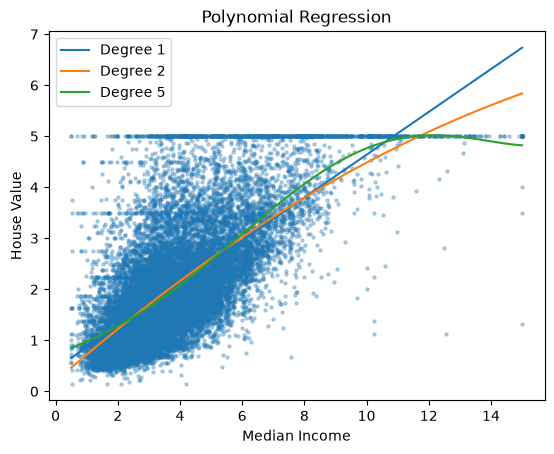

In [18]:
pt.scatter(X, y, s=5, alpha=0.3)

xs = pd.DataFrame({
    "MedInc": np.linspace(X["MedInc"].min(), X["MedInc"].max(), 200)
})

for d in [1, 2, 5]:
    poly, model = models[d]
    pt.plot(xs, model.predict(poly.transform(xs)), label=f"Degree {d}")

pt.xlabel("Median Income")
pt.ylabel("House Value")
pt.title("Polynomial Regression")
pt.legend()
pt.show()


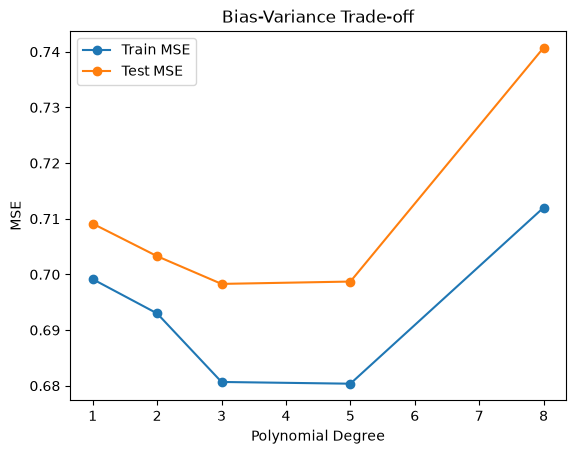

In [14]:

pt.plot(ress["Degree"], ress["Train MSE"], "o-", label="Train MSE")
pt.plot(ress["Degree"], ress["Test MSE"], "o-", label="Test MSE")

pt.xlabel("Polynomial Degree")
pt.ylabel("MSE")
pt.title("Bias-Variance Trade-off")
pt.legend()
pt.show()
